# Combinatorial Optimization Problems: Overview

## Setup

In [1]:
import matplotlib.pyplot as plt

from core.problems.archive.op import OPConfig, get_op_generator, visualize_op_instance
from core.problems.cvrp import CVRP, CVRPSampler
from core.problems.tsp import TSP, TSPSampler
from core.problems.tsp.solve import random_permutation

W0524 17:12:46.190000 15700 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


In [2]:
%load_ext autoreload
%autoreload 2

## Traveling Salesman Problem

Batch of TSP instances:
TSPInstance(
    locations=Tensor(shape=torch.Size([4, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
    batch_size=torch.Size([4]),
    device=None,
    is_shared=False)
------------------------------------------
Single TSP instance:
TSPInstance(
    locations=Tensor(shape=torch.Size([20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
    batch_size=torch.Size([]),
    device=None,
    is_shared=False)


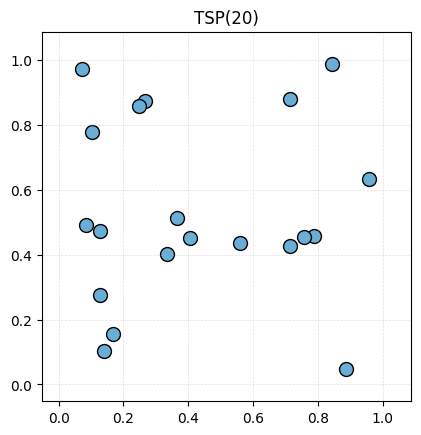

In [3]:
tsp_config = TSP(num_locations=20)
tsp_sampler = TSPSampler(tsp_config)
tsp_instance = tsp_sampler(4)

print("Batch of TSP instances:")
print(tsp_instance)

print("-" * 42)

print("Single TSP instance:")
print(tsp_instance[0])

tsp_instance[0].visualize()
plt.show()

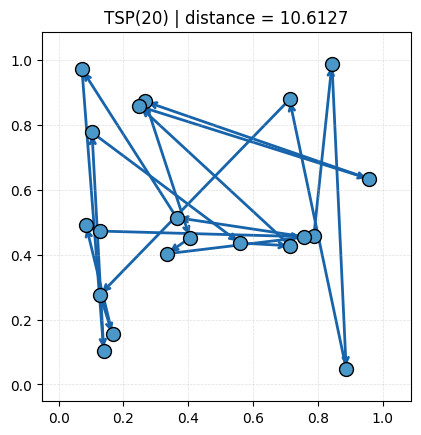

In [4]:
tsp_solution = random_permutation(tsp_instance)
tsp_solution[0].visualize()

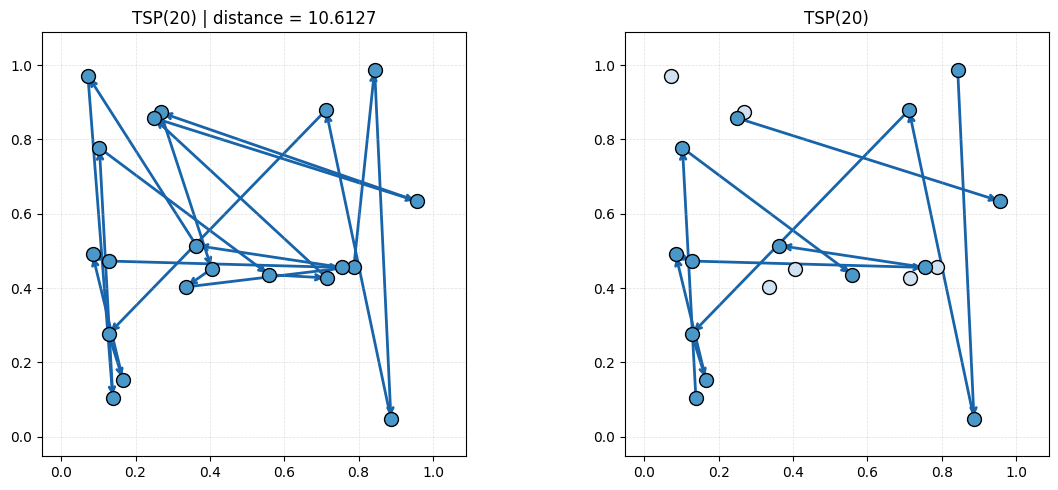

In [5]:
import torch

from core.problems.tsp.graph_solution import TSPGraphSolution

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

graph_solution = TSPGraphSolution.create_from_sequence(tsp_instance, tsp_solution.tour)
graph_solution[0].visualize(ax=axes[0])

partial_graph_solution = graph_solution.remove_nodes(
    torch.arange(5).unsqueeze(0).expand(*tsp_solution.batch_size, -1)
)
partial_graph_solution[0].visualize(ax=axes[1])

plt.tight_layout()
plt.show()

## Capacitated Vehicle Problem

Batch of CVRP instances:
CVRPInstance(
    capacity=Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.float32, is_shared=False),
    demand=Tensor(shape=torch.Size([4, 21]), device=cpu, dtype=torch.float32, is_shared=False),
    locations=Tensor(shape=torch.Size([4, 21, 2]), device=cpu, dtype=torch.float32, is_shared=False),
    batch_size=torch.Size([4]),
    device=None,
    is_shared=False)
------------------------------------------
Single CVRP instance:
CVRPInstance(
    capacity=Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
    demand=Tensor(shape=torch.Size([21]), device=cpu, dtype=torch.float32, is_shared=False),
    locations=Tensor(shape=torch.Size([21, 2]), device=cpu, dtype=torch.float32, is_shared=False),
    batch_size=torch.Size([]),
    device=None,
    is_shared=False)


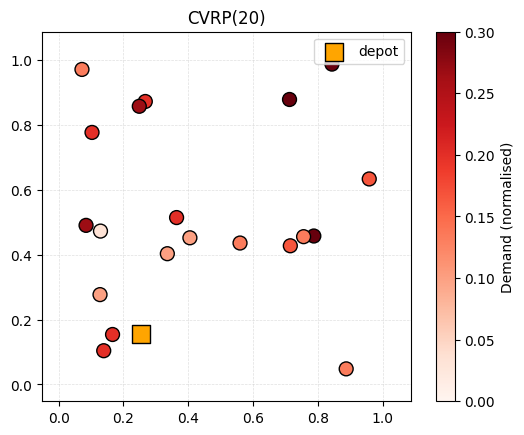

In [6]:
cvrp_config = CVRP.for_n(20)
cvrp_sampler = CVRPSampler(cvrp_config)
cvrp_batch = cvrp_sampler(4)

print("Batch of CVRP instances:")
print(cvrp_batch)

print("-" * 42)

print("Single CVRP instance:")
print(cvrp_batch[0])

cvrp_batch[0].visualize()
plt.show()

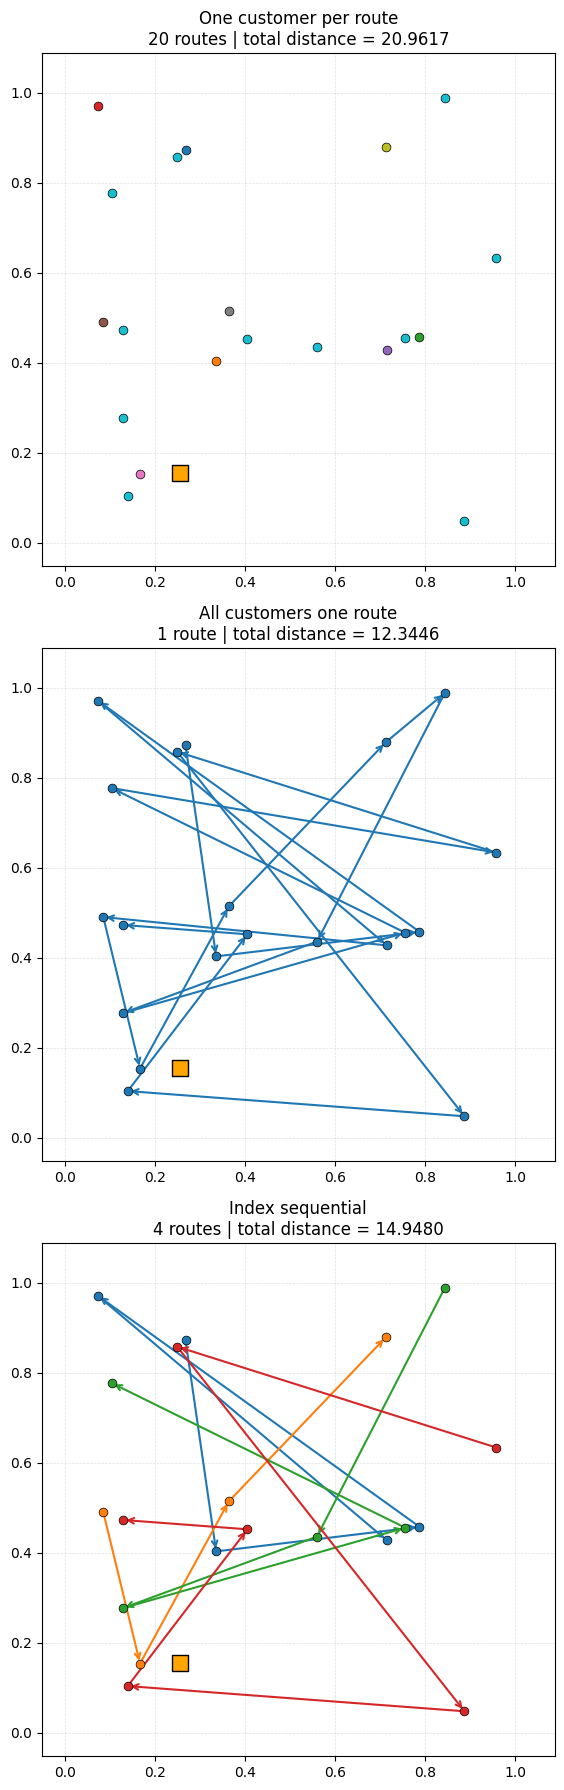

In [7]:
from core.problems.cvrp.solve import (
    CVRPSolveStrategy,
    all_customers_one_route,
    index_sequential,
    one_customer_per_route,
)

fig, axes = plt.subplots(3, 1, figsize=(6, 18))

strategies: list[tuple[CVRPSolveStrategy, str]] = [
    (one_customer_per_route, "One customer per route"),
    (all_customers_one_route, "All customers one route"),
    (index_sequential, "Index sequential"),
]

for ax, (strategy, title) in zip(axes, strategies):
    solution = strategy(cvrp_batch[0])
    solution.visualize(
        ax=ax, with_problem_size=False, depot_in_legend=False, with_route_labels=False
    )
    ax.set_title(f"{title}\n{ax.get_title()}")

plt.tight_layout()
plt.show()

## Orienteering Problem

**1. Constant**

TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([1, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([1, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([1, 20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=None,
    is_shared=False)
TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([]),
    device=None,
    is_shared=False)


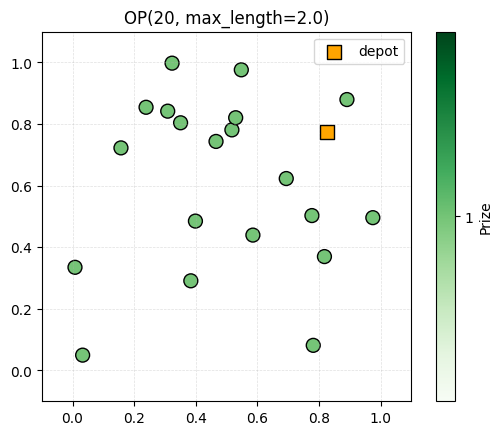

In [8]:
op_config = OPConfig(num_nodes=20, prize_type="const")
op_generator = get_op_generator(op_config)
op_generator.device = "cpu"
td = op_generator([1])
print(td)

print(td[0])

min_loc = op_generator.min_loc
max_loc = op_generator.max_loc

visualize_op_instance(td[0], min_loc, max_loc, prize_type="const")
plt.show()

**2. Uniform**

TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([1, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([1, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([1, 20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=None,
    is_shared=False)


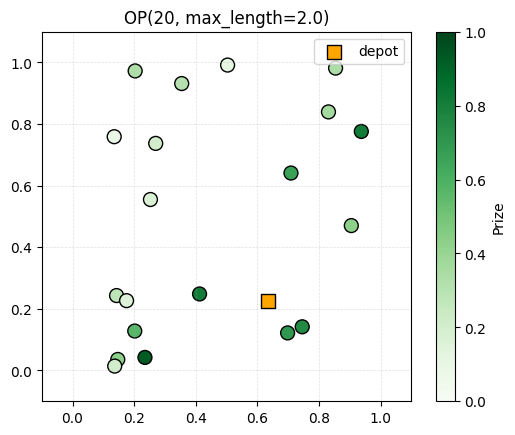

In [9]:
op_config = OPConfig(num_nodes=20, prize_type="unif")
op_generator = get_op_generator(op_config)
op_generator.device = "cpu"
td = op_generator([1])
print(td)

min_loc = op_generator.min_loc
max_loc = op_generator.max_loc

locations = td["locs"][0].cpu().numpy()
depot = td["depot"][0].cpu().numpy()
prizes = td["prize"][0].cpu().numpy()
max_length = td["max_length"][0].item()

visualize_op_instance(td[0], min_loc, max_loc, prize_type="unif")
plt.show()

**3. Distance**

TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([1, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([1, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([1, 20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=None,
    is_shared=False)


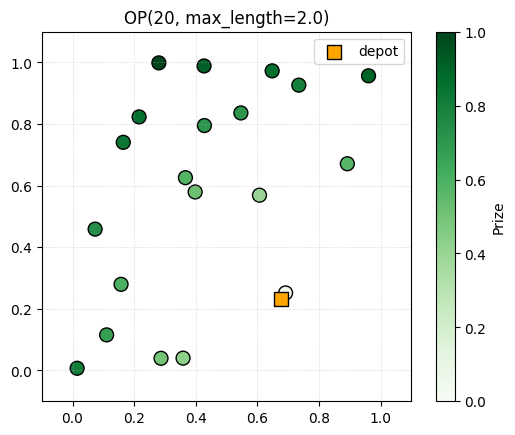

In [10]:
op_config = OPConfig(num_nodes=20, prize_type="dist")
op_generator = get_op_generator(op_config)
td = op_generator([1])
print(td)

min_loc = op_generator.min_loc
max_loc = op_generator.max_loc

visualize_op_instance(td[0], min_loc, max_loc, prize_type="dist")
plt.show()